In [1]:
"""Tasks
1.
Given a CSV file containing Zomato restaurant ratings, use pandas to detect outliers in the
 'user_rating' column using the IQR method and print the indices of the detected outliers.
2.
Create a boxplot for the 'order_amount' column from a Swiggy orders dataset using matplotlib,
 and visually identify any outliers present.<br><br><em><strong>Hint:</strong> Use plt.boxplot()
   and label your axes for clarity.</em>
3.
Apply winsorization to the 'transaction_amount' column in a Paytm transactions DataFrame to cap
 all values above the 95th percentile and below the 5th percentile, then display the updated column statistics.
4.
You have a DataFrame of Flipkart product prices stored as strings with currency symbols 
(e.g., '₹1,299'). Convert this column to numeric type using pandas, ensuring all non-numeric 
characters are removed.<br><br><em><strong>Hint:</strong> Use str.replace() and astype().</em>
5.
Fix the following code snippet where the 'is_premium' column in a Spotify user DataFrame is a 
mix of boolean, string, and integer types. Convert the entire column to boolean type, treating 
'True', 1, and 'yes' as True, and everything else as False."""

"Tasks\n1.\nGiven a CSV file containing Zomato restaurant ratings, use pandas to detect outliers in the\n 'user_rating' column using the IQR method and print the indices of the detected outliers.\n2.\nCreate a boxplot for the 'order_amount' column from a Swiggy orders dataset using matplotlib,\n and visually identify any outliers present.<br><br><em><strong>Hint:</strong> Use plt.boxplot()\n   and label your axes for clarity.</em>\n3.\nApply winsorization to the 'transaction_amount' column in a Paytm transactions DataFrame to cap\n all values above the 95th percentile and below the 5th percentile, then display the updated column statistics.\n4.\nYou have a DataFrame of Flipkart product prices stored as strings with currency symbols \n(e.g., '₹1,299'). Convert this column to numeric type using pandas, ensuring all non-numeric \ncharacters are removed.<br><br><em><strong>Hint:</strong> Use str.replace() and astype().</em>\n5.\nFix the following code snippet where the 'is_premium' column 

In [2]:
"""1.
Given a CSV file containing Zomato restaurant ratings, use pandas to detect outliers in the
 'user_rating' column using the IQR method and print the indices of the detected outliers."""


import pandas as pd

df = pd.read_csv(r"C:\Users\HP\Downloads\zomato.csv")

Q1 = df["user_rating"].quantile(0.25)
Q3 = df["user_rating"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["user_rating"] < lower_limit) |
    (df["user_rating"] > upper_limit)
]

print("Indices of outliers:")
print(outliers.index.tolist())
print(df)


Indices of outliers:
[13, 14]
    restaurant_id  restaurant_name  user_rating       city
0             101     Spice Garden          4.1  Ahmedabad
1             102      Urban Tadka          3.8     Mumbai
2             103      Pizza Point          4.3      Delhi
3             104       Green Bowl          3.9       Pune
4             105    Royal Biryani          4.2     Jaipur
5             106       Cafe Aroma          4.0    Udaipur
6             107    Food Junction          3.7      Surat
7             108  The Curry House          4.4  Bengaluru
8             109       Burger Hub          4.1     Mumbai
9             110      South Spice          3.6    Chennai
10            111  Tandoori Trails          4.0      Delhi
11            112      Noodle Nest          4.2       Pune
12            113     Sweet Treats          4.3  Ahmedabad
13            114  Coastal Kitchen          1.0        Goa
14            115       Mega Feast          5.0      Delhi


In [3]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


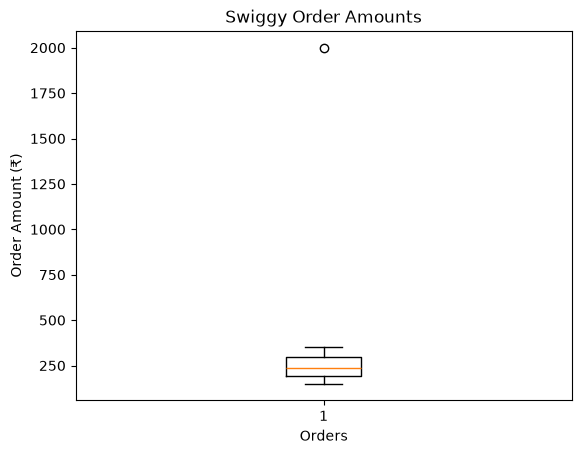

In [4]:
"""2.
Create a boxplot for the 'order_amount' column from a Swiggy orders dataset using matplotlib,
 and visually identify any outliers present.<br><br><em><strong>Hint:</strong> Use plt.boxplot()
   and label your axes for clarity.</em>"""

import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'order_amount': [150, 200, 250, 180, 300, 220, 190, 280, 350, 2000]
})

plt.boxplot(df['order_amount'])
plt.title('Swiggy Order Amounts')
plt.xlabel('Orders')
plt.ylabel('Order Amount (₹)')
plt.show()

In [5]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [6]:
"""3.
Apply winsorization to the 'transaction_amount' column in a Paytm transactions DataFrame to cap
 all values above the 95th percentile and below the 5th percentile, then display the updated column statistics."""

import pandas as pd
from scipy.stats.mstats import winsorize

df = pd.DataFrame({
    'transaction_amount': [
        100, 200, 300, 400, 500,
        600, 700, 800, 900, 5000
    ]
})

print(df)

lower = df['transaction_amount'].quantile(0.05)
upper = df['transaction_amount'].quantile(0.95)

print("5th Percentile:", lower)
print("95th Percentile:", upper)

df['transaction_amount'] = df['transaction_amount'].clip(
    lower=lower,
    upper=upper
)

print(df)

print(df['transaction_amount'].describe())

   transaction_amount
0                 100
1                 200
2                 300
3                 400
4                 500
5                 600
6                 700
7                 800
8                 900
9                5000
5th Percentile: 145.0
95th Percentile: 3154.9999999999955
   transaction_amount
0               145.0
1               200.0
2               300.0
3               400.0
4               500.0
5               600.0
6               700.0
7               800.0
8               900.0
9              3155.0
count      10.000000
mean      770.000000
std       874.709476
min       145.000000
25%       325.000000
50%       550.000000
75%       775.000000
max      3155.000000
Name: transaction_amount, dtype: float64


In [7]:
"""
4.
You have a DataFrame of Flipkart product prices stored as strings with currency symbols 
(e.g., '₹1,299'). Convert this column to numeric type using pandas, ensuring all non-numeric 
characters are removed.<br><br><em><strong>Hint:</strong> Use str.replace() and astype().</em>"""

import pandas as pd

df = pd.DataFrame({
    'price': ['₹1,299', '₹2,499', '₹999', '₹5,000', '₹799']
})

print(df)

df['price'] = df['price'].str.replace('₹', '', regex=False)
df['price'] = df['price'].str.replace(',', '', regex=False)

df['price'] = df['price'].astype(int)

print(df)

print(df['price'].dtype)


    price
0  ₹1,299
1  ₹2,499
2    ₹999
3  ₹5,000
4    ₹799
   price
0   1299
1   2499
2    999
3   5000
4    799
int64


In [8]:
"""5.
Fix the following code snippet where the 'is_premium' column in a Spotify user DataFrame is a 
mix of boolean, string, and integer types. Convert the entire column to boolean type, treating 
'True', 1, and 'yes' as True, and everything else as False."""

import pandas as pd

df = pd.DataFrame({
    'is_premium': [True, 'True', 1, 'yes', 'No', 0, 'False', 'random']
})

print(df)

df['is_premium'] = df['is_premium'].apply(
    lambda x: str(x).lower() in ['true', '1', 'yes']
)

print(df)

print(df['is_premium'].dtype)

  is_premium
0       True
1       True
2          1
3        yes
4         No
5          0
6      False
7     random
   is_premium
0        True
1        True
2        True
3        True
4       False
5       False
6       False
7       False
bool
